## Setup and configuration

In [1]:
%pip install -q datasets nltk scikit-learn matplotlib pandas joblib

In [2]:
import re, json, pickle, random, platform, warnings
from pathlib import Path
from functools import lru_cache
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import nltk
import sklearn
for pkg in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

SEED     = 42
N_TRAIN  = 20_000
N_TEST   = 4_000
LABELS   = {0: "Negative", 1: "Positive"}
random.seed(SEED); np.random.seed(SEED)

DATA_DIR, MODEL_DIR, RESULT_DIR = Path("data"), Path("models"), Path("results")
for d in (DATA_DIR, MODEL_DIR, RESULT_DIR):
    d.mkdir(exist_ok=True)
print("Setup complete.")

Setup complete.


## Corpus acquisition and train/test separation


In [3]:
from datasets import load_dataset

dataset = load_dataset("fancyzhx/amazon_polarity")
print(dataset)

train_data = dataset["train"].shuffle(seed=SEED).select(range(N_TRAIN))
test_data  = dataset["test"].shuffle(seed=SEED).select(range(N_TEST))

train_df = pd.DataFrame(train_data)
test_df  = pd.DataFrame(test_data)

for df in (train_df, test_df):
    df["text"] = (df["title"].fillna("") + " " + df["content"].fillna("")).str.strip()
    df["sentiment"] = df["label"].map(LABELS)

print("\nTrain:", train_df.shape, "| Test:", test_df.shape)
print("Missing texts  train/test:", train_df["text"].isna().sum(), "/", test_df["text"].isna().sum())
display(train_df[["text", "sentiment"]].head(5))

README.md:   0%|          | 0.00/6.81k [00:00<?, ?B/s]

amazon_polarity/train-00000-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  260MB            

amazon_polarity/train-00000-of-00004.par(…): downloading bytes:           |  0.00B            

amazon_polarity/train-00001-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  258MB            

amazon_polarity/train-00001-of-00004.par(…): downloading bytes:           |  0.00B            

amazon_polarity/train-00002-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  255MB            

... (5 outputs left out)

Generating train split:   0%|          | 0/3600000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'title', 'content'],
        num_rows: 3600000
    })
    test: Dataset({
        features: ['label', 'title', 'content'],
        num_rows: 400000
    })
})

Train: (20000, 5) | Test: (4000, 5)
Missing texts  train/test: 0 / 0


,text,sentiment
0,Anyone who likes this better than the Pekinpah is a moron. All the pretty people in this film. Even the Rudy charact...,Negative
1,Author seems mentally unstable I know that Tom Robbins has a loyal following and I started the book with high expect...,Negative
2,Spaetzle Noodles This type of spaetzle maker is easier to manuveur than the old press kind and much easier on the ha...,Positive
3,Cool product until the cats lost it . . . . My cats seemed to be amused to work for their food. One cat would roll t...,Positive
4,Works as expected I've had no problems running this with my Dell 8200 PC running Windows XP Home Edition which is ru...,Positive


In [4]:
overlap = set(train_df["text"]) & set(test_df["text"])
print("Texts present in both train and test subsets:", len(overlap))

train_df[["label", "title", "content"]].to_csv(DATA_DIR / "train.csv", index=False)
test_df[["label", "title", "content"]].to_csv(DATA_DIR / "test.csv", index=False)
print("Saved: data/train.csv and data/test.csv  (test = first", N_TEST, "rows of official test split after shuffle(seed=42))")

Texts present in both train and test subsets: 0
Saved: data/train.csv and data/test.csv  (test = first 4000 rows of official test split after shuffle(seed=42))


##Text preprocessing


In [5]:
NEGATIONS  = {"no", "not", "nor", "never"}
STOP_WORDS = set(stopwords.words("english")) - NEGATIONS
lemmatizer = WordNetLemmatizer()

@lru_cache(maxsize=None)
def lemmatize_word(word):
    """Verb pass then noun pass (default WordNet lemmatiser only handles nouns)."""
    return lemmatizer.lemmatize(lemmatizer.lemmatize(word, pos="v"), pos="n")

def expand_contractions(text):
    text = text.replace("’", "'")
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bcannot\b", "can not", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"n't\b", " not", text)
    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True, as_tokens=False):
    """Reusable preprocessing pipeline (Unit 2). Returns a string (or token list)."""
    if not isinstance(text, str):
        text = ""
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = expand_contractions(text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if len(t) > 1 or t in {"a", "i"}]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if lemmatize:
        tokens = [lemmatize_word(t) for t in tokens]
    return tokens if as_tokens else " ".join(tokens)

for s in ["This product is really good, and I love it!",
          "I did not enjoy this book.",
          "I don't recommend this product.",
          "This product is not bad.",
          "It <br /> can't be worse, see www.example.com :( 10/10 NOT!"]:
    print("Original :", s)
    print("Processed:", preprocess_text(s))
    print("-" * 70)

Original : This product is really good, and I love it!
Processed: product really good love
----------------------------------------------------------------------
Original : I did not enjoy this book.
Processed: not enjoy book
----------------------------------------------------------------------
Original : I don't recommend this product.
Processed: not recommend product
----------------------------------------------------------------------
Original : This product is not bad.
Processed: product not bad
----------------------------------------------------------------------
Original : It <br /> can't be worse, see www.example.com :( 10/10 NOT!
Processed: not worse see not
----------------------------------------------------------------------


In [6]:
for i in range(3):
    print(f"Review {i+1}  ({train_df['sentiment'].iloc[i]})")
    print("Original :", train_df["text"].iloc[i][:300])
    print("Processed:", preprocess_text(train_df["text"].iloc[i])[:300])
    print("-" * 70)

Review 1  (Negative)
Original : Anyone who likes this better than the Pekinpah is a moron. All the pretty people in this film. Even the Rudy character played by Michael Madsen. This is adapted from a Jim Thompson novel for cryin' out loud! These are supposed to be marginal characters, not fashion models. Though McQueen and McGraw 
Processed: anyone like better pekinpah moron pretty people film even rudy character play michael madsen adapt jim thompson novel cryin loud suppose marginal character not fashion model though mcqueen mcgraw attractive check mcqueen crummy prison haircut believable role baldwin bassinger seem like movie star tr
----------------------------------------------------------------------
Review 2  (Negative)
Original : Author seems mentally unstable I know that Tom Robbins has a loyal following and I started the book with high expectations. However, I did not enjoy this book as it was too much work to follow his confused logic. I think that he was under the influence

In [7]:
train_df["processed_text"] = train_df["text"].apply(preprocess_text)
test_df["processed_text"]  = test_df["text"].apply(preprocess_text)

train_df["lm_text"] = train_df["text"].apply(lambda t: preprocess_text(t, remove_stopwords=False, lemmatize=False))
test_df["lm_text"]  = test_df["text"].apply(lambda t: preprocess_text(t, remove_stopwords=False, lemmatize=False))

print("Empty after preprocessing  train/test:",
      (train_df["processed_text"] == "").sum(), "/", (test_df["processed_text"] == "").sum())

train_df[["label", "sentiment", "text", "processed_text"]].to_csv(DATA_DIR / "train_processed.csv", index=False)
test_df[["label", "sentiment", "text", "processed_text"]].to_csv(DATA_DIR / "test_processed.csv", index=False)
display(train_df[["text", "processed_text", "sentiment"]].head(5))

Empty after preprocessing  train/test: 1 / 0


,text,processed_text,sentiment
0,Anyone who likes this better than the Pekinpah is a moron. All the pretty people in this film. Even the Rudy charact...,anyone like better pekinpah moron pretty people film even rudy character play michael madsen adapt jim thompson nove...,Negative
1,Author seems mentally unstable I know that Tom Robbins has a loyal following and I started the book with high expect...,author seem mentally unstable know tom robbins loyal follow start book high expectation however not enjoy book much ...,Negative
2,Spaetzle Noodles This type of spaetzle maker is easier to manuveur than the old press kind and much easier on the ha...,spaetzle noodle type spaetzle maker easier manuveur old press kind much easier hand difference new spaetzle maker ma...,Positive
3,Cool product until the cats lost it . . . . My cats seemed to be amused to work for their food. One cat would roll t...,cool product cat lose cat seem amuse work food one cat would roll ball paw nose would walk behind eat whatever fell ...,Positive
4,Works as expected I've had no problems running this with my Dell 8200 PC running Windows XP Home Edition which is ru...,work expect no problem run dell pc run window xp home edition run addon usb card hub port version connect buy year a...,Positive


## Corpus exploration and statistics

In [8]:
def corpus_stats(df):
    proc = [t for s in df["processed_text"] for t in s.split()]
    raw  = [t for s in df["lm_text"] for t in s.split()]
    cnt  = Counter(proc)
    return {
        "documents": len(df),
        "classes": df["label"].nunique(),
        "word tokens (stop-words kept)": len(raw),
        "vocabulary (stop-words kept)": len(set(raw)),
        "tokens after preprocessing": len(proc),
        "vocabulary after preprocessing": len(cnt),
        "words occurring once (hapax)": sum(1 for c in cnt.values() if c == 1),
        "avg tokens / review (processed)": round(len(proc) / len(df), 2),
    }

stats = pd.DataFrame({"train": corpus_stats(train_df), "test": corpus_stats(test_df)})
display(stats)

train_vocab = set(t for s in train_df["processed_text"] for t in s.split())
test_tokens = [t for s in test_df["processed_text"] for t in s.split()]
oov = np.mean([t not in train_vocab for t in test_tokens])
print(f"Out-of-vocabulary rate of test tokens w.r.t. the training vocabulary: {oov:.2%}")

dist = pd.DataFrame({
    "train_count": train_df["sentiment"].value_counts(),
    "train_%": (train_df["sentiment"].value_counts(normalize=True) * 100).round(2),
    "test_count": test_df["sentiment"].value_counts(),
    "test_%": (test_df["sentiment"].value_counts(normalize=True) * 100).round(2),
})
print("\nClass distribution")
display(dist)

,train,test
documents,20000.00,4000.00
classes,2.00,2.00
word tokens (stop-words kept),1588001.00,313113.00
vocabulary (stop-words kept),47529.00,20512.00
tokens after preprocessing,819557.00,162322.00
vocabulary after preprocessing,37986.00,15987.00
words occurring once (hapax),18607.00,7889.00
avg tokens / review (processed),40.98,40.58


Out-of-vocabulary rate of test tokens w.r.t. the training vocabulary: 3.10%

Class distribution


,train_count,train_%,test_count,test_%
sentiment,,,,
Negative,10008,50.04,1962,49.05
Positive,9992,49.96,2038,50.95


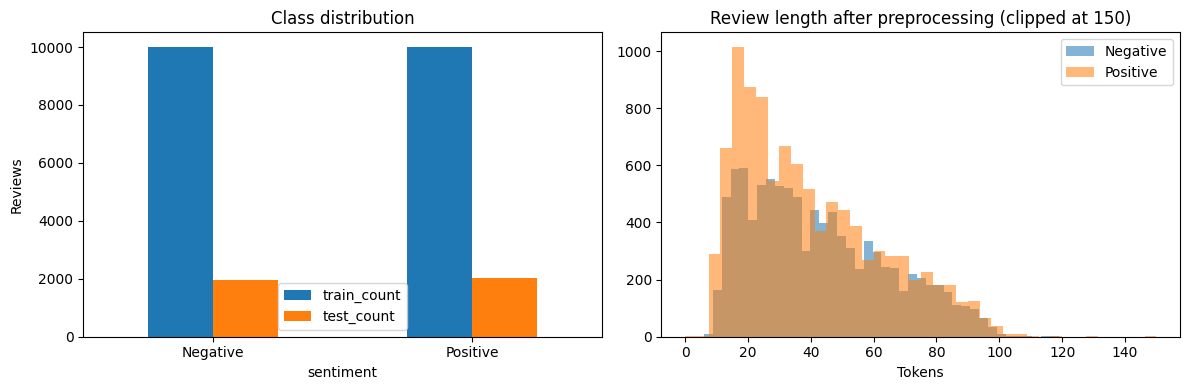

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dist[["train_count", "test_count"]].plot(kind="bar", ax=ax[0], rot=0)
ax[0].set_title("Class distribution"); ax[0].set_ylabel("Reviews")

train_df["n_tokens"] = train_df["processed_text"].str.split().str.len()
for lab, grp in train_df.groupby("sentiment"):
    ax[1].hist(grp["n_tokens"].clip(upper=150), bins=40, alpha=0.55, label=lab)
ax[1].set_title("Review length after preprocessing (clipped at 150)")
ax[1].set_xlabel("Tokens"); ax[1].legend()
plt.tight_layout(); plt.show()

In [10]:
def top_words(texts, n=20):
    return Counter(t for s in texts for t in s.split()).most_common(n)

tw = pd.DataFrame({
    "overall":  [f"{w} ({c})" for w, c in top_words(train_df["processed_text"])],
    "Negative": [f"{w} ({c})" for w, c in top_words(train_df.loc[train_df.label == 0, "processed_text"])],
    "Positive": [f"{w} ({c})" for w, c in top_words(train_df.loc[train_df.label == 1, "processed_text"])],
})
display(tw)

,overall,Negative,Positive
0,not (23771),not (16031),not (7740)
1,book (12417),book (5891),book (6526)
2,one (7968),one (4070),great (4689)
3,get (6770),get (3862),one (3898)
4,like (6578),like (3325),good (3340)
5,great (6002),buy (3276),like (3253)
6,good (5817),would (3135),read (2978)
7,buy (5202),make (2602),love (2911)
8,read (5180),no (2522),get (2908)
9,would (4959),time (2519),make (2298)


##  N-gram analysis


In [11]:
from sklearn.feature_extraction.text import CountVectorizer

def ngram_counts(texts, n):
    vec = CountVectorizer(ngram_range=(n, n))
    X = vec.fit_transform(texts)
    return pd.Series(np.asarray(X.sum(axis=0)).ravel(), index=vec.get_feature_names_out())

pos_texts = train_df.loc[train_df.label == 1, "processed_text"]
neg_texts = train_df.loc[train_df.label == 0, "processed_text"]

NG = {}
for n in (1, 2, 3):
    p, q = ngram_counts(pos_texts, n), ngram_counts(neg_texts, n)
    t = pd.concat([p.rename("pos"), q.rename("neg")], axis=1).fillna(0).astype(int)
    t["total"] = t["pos"] + t["neg"]
    NG[n] = t

names = {1: "UNIGRAMS", 2: "BIGRAMS", 3: "TRIGRAMS"}
top = pd.DataFrame({names[n]: [f"{k} ({v})" for k, v in NG[n]["total"].nlargest(15).items()] for n in (1, 2, 3)})
print("TOP 15 N-GRAMS (all training reviews)")
display(top)

TOP 15 N-GRAMS (all training reviews)


,UNIGRAMS,BIGRAMS,TRIGRAMS
0,not (23771),would not (830),not waste money (209)
1,book (12417),could not (760),would not recommend (164)
2,one (7968),read book (751),not waste time (119)
3,get (6770),not buy (715),waste time money (105)
4,like (6578),not work (656),not worth money (103)
5,great (6002),not even (646),book ever read (94)
6,good (5817),not get (562),could not get (84)
7,buy (5202),year old (557),could not put (79)
8,read (5180),book not (546),would not buy (74)
9,would (4959),waste money (514),highly recommend book (73)


In [12]:
print("TOP 10 N-GRAMS PER CLASS")
for n in (1, 2, 3):
    per_class = pd.DataFrame({
        "Negative": [f"{k} ({v})" for k, v in NG[n]["neg"].nlargest(10).items()],
        "Positive": [f"{k} ({v})" for k, v in NG[n]["pos"].nlargest(10).items()],
    })
    print(f"\n{names[n]}")
    display(per_class)

TOP 10 N-GRAMS PER CLASS

UNIGRAMS


,Negative,Positive
0,not (16031),not (7740)
1,book (5891),book (6526)
2,one (4070),great (4689)
3,get (3862),one (3898)
4,like (3325),good (3340)
5,buy (3276),like (3253)
6,would (3135),read (2978)
7,make (2602),love (2911)
8,no (2522),get (2908)
9,time (2519),make (2298)



BIGRAMS


,Negative,Positive
0,would not (669),highly recommend (451)
1,not buy (667),read book (438)
2,not work (598),one best (329)
3,not even (540),year old (303)
4,waste money (509),could not (275)
5,could not (485),great book (241)
6,not worth (427),work great (231)
7,not get (381),would recommend (202)
8,book not (361),book read (197)
9,not waste (359),recommend book (193)



TRIGRAMS


,Negative,Positive
0,not waste money (209),could not put (73)
1,would not recommend (144),highly recommend book (73)
2,not waste time (117),book ever read (55)
3,waste time money (104),would highly recommend (52)
4,not worth money (102),best book ever (44)
5,could not get (75),recommend book anyone (43)
6,would not buy (70),one best book (42)
7,not buy book (41),not go wrong (35)
8,book ever read (39),would recommend anyone (35)
9,not buy product (39),would recommend book (34)



Characteristic bigrams (min count 20)


,Negative-specific,Positive-specific
0,"waste money (neg=509, pos=5)","recommend everyone (pos=28, neg=0)"
1,"zero star (neg=61, pos=0)","amaze book (pos=27, neg=0)"
2,"not waste (neg=359, pos=5)","excellent product (pos=27, neg=0)"
3,"complete waste (neg=48, pos=0)","definitely recommend (pos=45, neg=1)"
4,"extremely disappoint (neg=36, pos=0)","great toy (pos=22, neg=0)"
5,"buyer beware (neg=69, pos=1)","overall great (pos=22, neg=0)"
6,"big disappointment (neg=33, pos=0)","must read (pos=132, neg=5)"
7,"piece crap (neg=33, pos=0)","edge seat (pos=21, neg=0)"
8,"waste time (neg=335, pos=9)","like charm (pos=20, neg=0)"
9,"poorly design (neg=30, pos=0)","great value (pos=39, neg=1)"



Characteristic trigrams (min count 8)


,Negative-specific,Positive-specific
0,"not waste money (neg=209, pos=0)","highly recommend book (pos=73, neg=0)"
1,"waste time money (neg=104, pos=1)","book must read (pos=19, neg=0)"
2,"not worth money (neg=102, pos=1)","highly recommend product (pos=19, neg=0)"
3,"not waste time (neg=117, pos=2)","work like charm (pos=19, neg=0)"
4,"not recommend anyone (neg=37, pos=0)","must read anyone (pos=17, neg=0)"
5,"not worth time (neg=32, pos=0)","must read book (pos=15, neg=0)"
6,"worst book ever (neg=31, pos=0)","great product great (pos=14, neg=0)"
7,"waste money time (neg=29, pos=0)","highly recommend anyone (pos=14, neg=0)"
8,"waste money buy (neg=27, pos=0)","highly recommend movie (pos=14, neg=0)"
9,"waste money not (neg=27, pos=0)","bring back memory (pos=12, neg=0)"


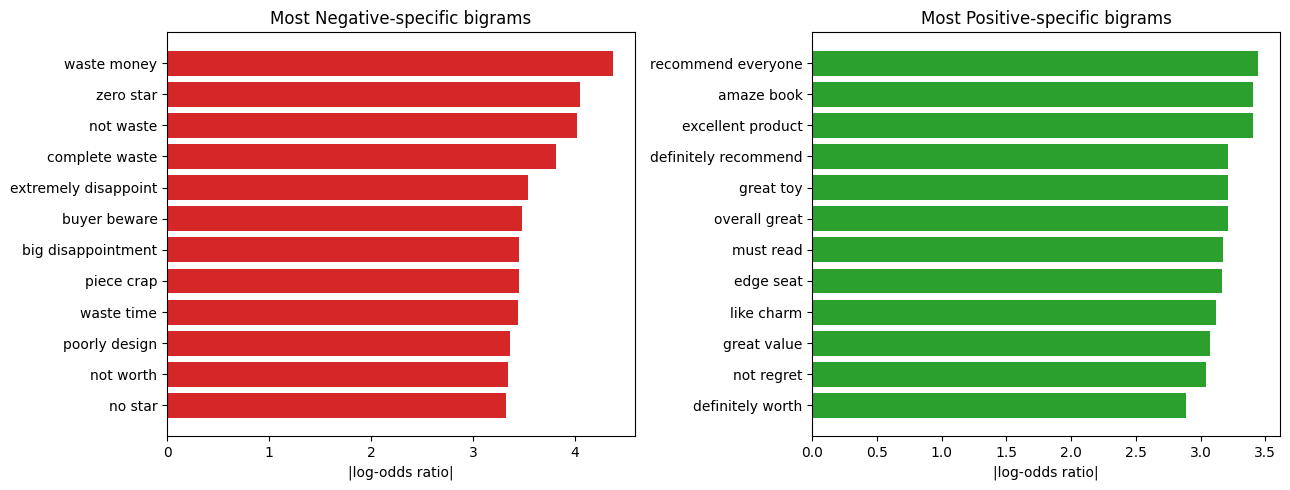

In [13]:
def characteristic(n, min_count, top_n=12, alpha=1.0):
    t = NG[n]
    P, N = t["pos"].sum(), t["neg"].sum()
    t = t[t["total"] >= min_count].copy()
    t["log_odds"] = np.log((t["pos"] + alpha) / P) - np.log((t["neg"] + alpha) / N)
    return t.nlargest(top_n, "log_odds"), t.nsmallest(top_n, "log_odds")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for n, min_c in ((2, 20), (3, 8)):
    pos_top, neg_top = characteristic(n, min_c)
    print(f"\nCharacteristic {names[n].lower()} (min count {min_c})")
    display(pd.DataFrame({
        "Negative-specific": [f"{k} (neg={int(r.neg)}, pos={int(r.pos)})" for k, r in neg_top.iterrows()],
        "Positive-specific": [f"{k} (pos={int(r.pos)}, neg={int(r.neg)})" for k, r in pos_top.iterrows()],
    }))

pos_b, neg_b = characteristic(2, 20)
axes[0].barh(neg_b.index[::-1], -neg_b["log_odds"][::-1], color="tab:red");   axes[0].set_title("Most Negative-specific bigrams")
axes[1].barh(pos_b.index[::-1],  pos_b["log_odds"][::-1], color="tab:green"); axes[1].set_title("Most Positive-specific bigrams")
for a in axes: a.set_xlabel("|log-odds ratio|")
plt.tight_layout(); plt.show()

## N-gram language model and next-word prediction


In [14]:
BOS, EOS = "<s>", "</s>"
uni = Counter()
bi, tri = defaultdict(Counter), defaultdict(Counter)

for text in train_df["lm_text"]:
    toks = [BOS, BOS] + text.split() + [EOS]
    uni.update(toks[2:])
    for i in range(2, len(toks)):
        bi[toks[i - 1]][toks[i]] += 1
        tri[(toks[i - 2], toks[i - 1])][toks[i]] += 1

bi, tri = dict(bi), dict(tri)                       # freeze (no accidental key creation)
bi_tot  = {k: sum(v.values()) for k, v in bi.items()}
tri_tot = {k: sum(v.values()) for k, v in tri.items()}
N_UNI, V = sum(uni.values()), len(uni) + 1
print(f"Vocabulary: {len(uni):,} | bigram contexts: {len(bi):,} | trigram contexts: {len(tri):,}")

Vocabulary: 47,530 | bigram contexts: 47,530 | trigram contexts: 495,478


In [15]:
def predict_next_words(context, top_n=5, alpha=0.4):
    """Next-word prediction with stupid backoff: trigram -> bigram -> unigram."""
    toks = [BOS, BOS] + preprocess_text(context, remove_stopwords=False, lemmatize=False, as_tokens=True)
    w1, w2 = toks[-2], toks[-1]
    scores = {}
    if (w1, w2) in tri:
        tot = tri_tot[(w1, w2)]
        for w, c in tri[(w1, w2)].items():
            scores[w] = (c / tot, "trigram")
    if w2 in bi:
        tot = bi_tot[w2]
        for w, c in bi[w2].items():
            scores.setdefault(w, (alpha * c / tot, "bigram"))
    if not scores:                                   # unknown word -> unigram fallback
        for w, c in uni.most_common(top_n):
            scores[w] = (alpha ** 2 * c / N_UNI, "unigram")
    ranked = sorted(scores.items(), key=lambda kv: -kv[1][0])
    return [(w, s, src) for w, (s, src) in ranked if w != BOS][:top_n]

def show_prediction(prompt, top_n=5):
    print(f'Prompt: "{prompt}"')
    for w, s, src in predict_next_words(prompt, top_n):
        print(f"    {w:<14} score={s:.4f}  [{src}]")

prompts = ["i would highly", "this product is", "waste of", "do not", "the battery", "works", "i love", "xyzqwerty"]
for p in prompts:
    show_prediction(p); print()

Prompt: "i would highly"
    recommend      score=0.9091  [trigram]
    recommended    score=0.0812  [bigram]
    suggest        score=0.0303  [trigram]
    rate           score=0.0152  [trigram]
    highly         score=0.0152  [trigram]

Prompt: "this product is"
    not            score=0.1077  [trigram]
    a              score=0.0821  [trigram]
    great          score=0.0667  [trigram]
    that           score=0.0410  [trigram]
    good           score=0.0308  [trigram]

Prompt: "waste of"
    money          score=0.4382  [trigram]
    time           score=0.3303  [trigram]
    my             score=0.0719  [trigram]
    a              score=0.0225  [trigram]
    this           score=0.0140  [bigram]

Prompt: "do not"
    buy            score=0.1156  [trigram]
    waste          score=0.0785  [trigram]
    know           score=0.0729  [trigram]
    have           score=0.0579  [trigram]
    think          score=0.0416  [trigram]

Prompt: "the battery"
    life           score=0.11

In [16]:
def interp_prob(w1, w2, w, lam):
    l3, l2, l1 = lam
    p_uni = (uni.get(w, 0) + 1) / (N_UNI + V)                                  # add-one smoothed unigram
    p_bi  = bi.get(w2, {}).get(w, 0) / bi_tot[w2] if w2 in bi_tot else 0.0
    p_tri = tri.get((w1, w2), {}).get(w, 0) / tri_tot[(w1, w2)] if (w1, w2) in tri_tot else 0.0
    return l3 * p_tri + l2 * p_bi + l1 * p_uni

def perplexity(texts, lam):
    log_p, n = 0.0, 0
    for text in texts:
        toks = [BOS, BOS] + text.split() + [EOS]
        for i in range(2, len(toks)):
            log_p += np.log(interp_prob(toks[i - 2], toks[i - 1], toks[i], lam)); n += 1
    return float(np.exp(-log_p / n))

held_out = test_df["lm_text"].head(1000)
ppl = {"unigram": perplexity(held_out, (0, 0, 1)),
       "bigram (0.7/0.3)": perplexity(held_out, (0, 0.7, 0.3)),
       "trigram (0.5/0.3/0.2)": perplexity(held_out, (0.5, 0.3, 0.2))}
print("Perplexity on 1,000 held-out test reviews (lower is better)")
display(pd.Series(ppl, name="perplexity").round(1).to_frame())

Perplexity on 1,000 held-out test reviews (lower is better)


,perplexity
unigram,969.6
bigram (0.7/0.3),408.4
trigram (0.5/0.3/0.2),434.0


## Bag of Words + classifier


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import StratifiedKFold, cross_val_score

X_train_text, y_train = train_df["processed_text"], train_df["label"]
X_test_text,  y_test  = test_df["processed_text"],  test_df["label"]

def bow_pipeline(clf, ngram=(1, 1), max_features=10_000):
    return Pipeline([("bow", CountVectorizer(ngram_range=ngram, max_features=max_features)), ("clf", clf)])

candidates = {
    "BoW(1-gram, 10k) + MultinomialNB":           bow_pipeline(MultinomialNB()),
    "BoW(1-gram, 10k) + LogReg (baseline)":       bow_pipeline(LogisticRegression(max_iter=1000, random_state=SEED)),
    "BoW(1-2gram, 20k) + MultinomialNB":          bow_pipeline(MultinomialNB(), (1, 2), 20_000),
    "BoW(1-2gram, 20k) + LogReg C=1":             bow_pipeline(LogisticRegression(max_iter=1000, random_state=SEED), (1, 2), 20_000),
    "BoW(1-2gram, 20k) + LogReg C=0.1":           bow_pipeline(LogisticRegression(C=0.1, max_iter=1000, random_state=SEED), (1, 2), 20_000),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, pipe in candidates.items():
    scores = cross_val_score(pipe, X_train_text, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    rows.append({"model": name, "cv_accuracy_mean": scores.mean(), "cv_accuracy_std": scores.std()})
cv_results = pd.DataFrame(rows).sort_values("cv_accuracy_mean", ascending=False).reset_index(drop=True)
display(cv_results.round(4))

best_name = cv_results.loc[0, "model"]
print("Selected by cross-validation on TRAIN only:", best_name)

,model,cv_accuracy_mean,cv_accuracy_std
0,"BoW(1-2gram, 20k) + LogReg C=0.1",0.8791,0.0038
1,"BoW(1-2gram, 20k) + LogReg C=1",0.8766,0.0052
2,"BoW(1-2gram, 20k) + MultinomialNB",0.8634,0.0045
3,"BoW(1-gram, 10k) + LogReg (baseline)",0.8552,0.0039
4,"BoW(1-gram, 10k) + MultinomialNB",0.8380,0.0072


Selected by cross-validation on TRAIN only: BoW(1-2gram, 20k) + LogReg C=0.1


In [18]:
final_model = clone(candidates[best_name]).fit(X_train_text, y_train)
vec = final_model.named_steps["bow"]
print("Bag-of-Words matrix (train):", vec.transform(X_train_text).shape, "| vocabulary size:", len(vec.vocabulary_))

Bag-of-Words matrix (train): (20000, 20000) | vocabulary size: 20000


## Final evaluation on unseen test data


Model: BoW(1-2gram, 20k) + LogReg C=0.1

Accuracy        : 0.8838
Macro Precision : 0.8838
Macro Recall    : 0.8836
Macro F1-score  : 0.8837

              precision    recall  f1-score   support

    Negative     0.8868    0.8746    0.8807      1962
    Positive     0.8809    0.8925    0.8867      2038

    accuracy                         0.8838      4000
   macro avg     0.8838    0.8836    0.8837      4000
weighted avg     0.8838    0.8838    0.8837      4000



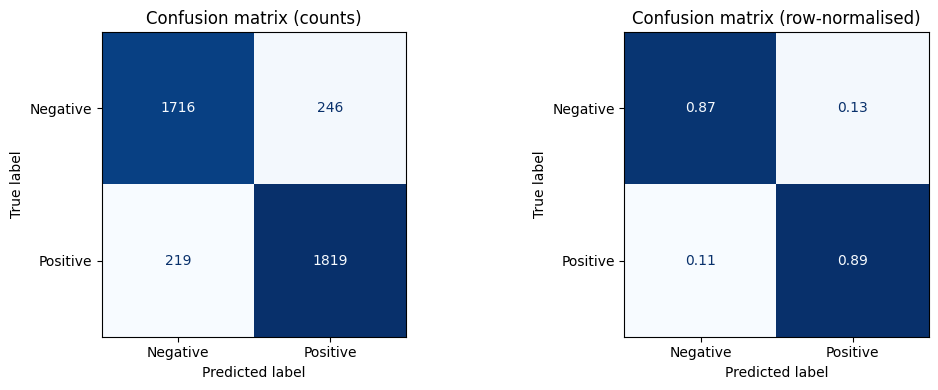

In [19]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

y_pred  = final_model.predict(X_test_text)
p_pos   = final_model.predict_proba(X_test_text)[:, 1]

acc = accuracy_score(y_test, y_pred)
p_m, r_m, f_m, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
p_c, r_c, f_c, s_c = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], zero_division=0)

print(f"Model: {best_name}\n")
print(f"Accuracy        : {acc:.4f}")
print(f"Macro Precision : {p_m:.4f}")
print(f"Macro Recall    : {r_m:.4f}")
print(f"Macro F1-score  : {f_m:.4f}\n")
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=["Negative", "Positive"], digits=4))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(ax=ax[0], cmap="Blues", values_format="d", colorbar=False)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=[0, 1], normalize="true"),
                       display_labels=["Negative", "Positive"]).plot(ax=ax[1], cmap="Blues", values_format=".2f", colorbar=False)
ax[0].set_title("Confusion matrix (counts)"); ax[1].set_title("Confusion matrix (row-normalised)")
plt.tight_layout(); plt.show()

metrics = {"model": best_name, "accuracy": acc, "macro_precision": p_m, "macro_recall": r_m, "macro_f1": f_m,
           "per_class": {LABELS[i]: {"precision": p_c[i], "recall": r_c[i], "f1": f_c[i], "support": int(s_c[i])} for i in (0, 1)},
           "confusion_matrix": cm.tolist(), "n_test": int(len(y_test))}

In [20]:
pred_df = test_df[["text", "label"]].copy()
pred_df["predicted"] = y_pred
pred_df["p_positive"] = p_pos
pred_df["correct"] = pred_df["label"] == pred_df["predicted"]

def view(df):
    return pd.DataFrame({
        "review": df["text"].str.slice(0, 110) + "...",
        "actual": df["label"].map(LABELS),
        "predicted": df["predicted"].map(LABELS),
        "P(positive)": df["p_positive"].round(3),
        "result": np.where(df["correct"], "correct", "WRONG"),
    })

print("FIRST 10 TEST REVIEWS")
display(view(pred_df.head(10)))

conf = (pred_df["p_positive"] - 0.5).abs()
print("5 CORRECT predictions with highest confidence")
display(view(pred_df[pred_df.correct].assign(c=conf).nlargest(5, "c")))
print("5 WRONG predictions with highest confidence")
display(view(pred_df[~pred_df.correct].assign(c=conf).nlargest(5, "c")))

FIRST 10 TEST REVIEWS


,review,actual,predicted,P(positive),result
0,Damaged Product The product works fine. I ordered the more exprensive one after I read reviews from others on ...,Positive,Positive,0.732,correct
1,A waste of time and money This book is so useless that I feel compelled to write a review to warn others to st...,Negative,Negative,0.053,correct
2,"Scattered, Out-of-Date, The authors attempt an ambitious goal of covering many SOA topics - but their resultin...",Negative,Negative,0.108,correct
3,Horrible Customer Service & Product I ordered this product and did recieve then a couple months later it broke...,Negative,Negative,0.021,correct
4,Is the joke on me? I hated this movie. It was so silly. The girl made the cult look more stupid than they alre...,Negative,Negative,0.001,correct
5,"Good Product, Easy to use Product was easy to use to assemble.Product supported my weight (180 lb) and was eas...",Positive,Positive,0.993,correct
6,"How you do to that CD,it's great,not bad 1.Music-I don't like it,but too overplayed for this CD-2/5 stars2.Mos...",Positive,Positive,0.701,correct
7,Good product! The other plastic garages and service stations that we have purchased in the past were made so p...,Positive,Positive,0.700,correct
8,"Hey ""A music fan from California, US "" Nirvana only got popular after cobain killed himself? Obviously you're ...",Positive,Positive,0.709,correct
9,"One fire... Tracy knows how to get you on your feet and dancing! This is an amazing effort from Tracy Young, a...",Positive,Positive,0.857,correct


5 CORRECT predictions with highest confidence


,review,actual,predicted,P(positive),result
2806,Total Waste of Money I'm so sorry that I paid about $15 for this DVD at a local store. It's not even worth 50 ...,Negative,Negative,0.0,correct
2640,Don't buy this juicer! My co-worker and I both bought this same juicer from Costco two years ago and we loved ...,Negative,Negative,0.0,correct
3287,"Absolute junk! The first AVP was watchable, but this sequel is the worst movie I've seen in many years. Not on...",Negative,Negative,0.0,correct
3296,Horrible customer service and BAD phone We had a similar problem...my girlfriend's wings screen went out after...,Negative,Negative,0.0,correct
431,Worst product Some serious problem with the lamp. Probably the worst thing I have purchased on Amazon.1. sever...,Negative,Negative,0.0,correct


5 WRONG predictions with highest confidence


,review,actual,predicted,P(positive),result
2617,"thilly-willy war songs Boy, this is great! Almost my favorite is the last song (performed live!) with its bril...",Negative,Positive,1.000,WRONG
1334,Boring Very boring. Im not a book reader. Thats why i purchased the audiobook. Compared to anything else done ...,Positive,Negative,0.001,WRONG
2408,a bit of a departure A lot of people are not pleased with the direction the Blood Brothers took on this one. I...,Positive,Negative,0.002,WRONG
940,"Highway robbery!! For the love of god, do NOT buy the Star Trek Action Pack or half the games within from the ...",Positive,Negative,0.004,WRONG
417,"Up to usual standards! The standards being excellent! This is a warm, witty, and charming example of mystery w...",Negative,Positive,0.996,WRONG


## Error analysis


In [21]:
tn, fp, fn, tp = cm.ravel()
print(f"Misclassified: {fp + fn} of {len(y_test)}  ({(fp + fn) / len(y_test):.2%})")
print(f"  False Positives (Negative review predicted Positive): {fp}")
print(f"  False Negatives (Positive review predicted Negative): {fn}\n")

err = pred_df.copy()
err["wrong"] = ~err["correct"]
err["n_tokens"] = test_df["processed_text"].str.split().str.len().values
err["length_bucket"] = pd.qcut(err["n_tokens"], 4, duplicates="drop")
err["has_contrast"] = test_df["text"].str.lower().str.contains(r"\b(?:but|however|although|though|except|unfortunately)\b").values
err["has_negation"] = test_df["processed_text"].str.contains(r"\b(?:not|no|never|nor)\b").values

print("Error rate by review length (quartiles of #tokens)")
display(err.groupby("length_bucket")["wrong"].agg(["mean", "size"]).rename(columns={"mean": "error_rate", "size": "reviews"}).round(3))
print("Error rate with / without contrast words (mixed opinions)")
display(err.groupby("has_contrast")["wrong"].agg(["mean", "size"]).rename(columns={"mean": "error_rate", "size": "reviews"}).round(3))
print("Error rate with / without negation words")
display(err.groupby("has_negation")["wrong"].agg(["mean", "size"]).rename(columns={"mean": "error_rate", "size": "reviews"}).round(3))

Misclassified: 465 of 4000  (11.62%)
  False Positives (Negative review predicted Positive): 246
  False Negatives (Positive review predicted Negative): 219

Error rate by review length (quartiles of #tokens)


,error_rate,reviews
length_bucket,,
"(6.999, 23.0]",0.092,1093
"(23.0, 36.0]",0.122,948
"(36.0, 55.0]",0.112,963
"(55.0, 111.0]",0.141,996


Error rate with / without contrast words (mixed opinions)


,error_rate,reviews
has_contrast,,
False,0.094,2052
True,0.140,1948


Error rate with / without negation words


,error_rate,reviews
has_negation,,
False,0.096,1327
True,0.126,2673


In [22]:
clf = final_model.named_steps["clf"]
feature_names = np.array(vec.get_feature_names_out())
weights = clf.coef_[0] if hasattr(clf, "coef_") else clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
order = np.argsort(weights)
print("Strongest NEGATIVE features:", ", ".join(feature_names[order[:20]]))
print("Strongest POSITIVE features:", ", ".join(feature_names[order[::-1][:20]]))

print("\nMISCLASSIFIED REVIEWS WITH CONTRAST WORDS (mixed opinions)")
mixed = err[err.wrong & err.has_contrast].copy()
mixed["c"] = (mixed["p_positive"] - 0.5).abs()
display(view(mixed.nlargest(6, "c")))

err[err.wrong][["text", "label", "predicted", "p_positive"]].to_csv(RESULT_DIR / "misclassified_reviews.csv", index=False)

Strongest NEGATIVE features: waste, not worth, disappoint, terrible, bore, poor, not recommend, disappointment, return, worst, horrible, unfortunately, useless, fail, not buy, not good, poorly, not great, not work, trash
Strongest POSITIVE features: not disappoint, awesome, excellent, not bad, perfect, great, wonderful, amaze, easy, complaint, love, no problem, fantastic, sturdy, best, favorite, definitely, beautiful, outstanding, solid

MISCLASSIFIED REVIEWS WITH CONTRAST WORDS (mixed opinions)


,review,actual,predicted,P(positive),result
1334,Boring Very boring. Im not a book reader. Thats why i purchased the audiobook. Compared to anything else done ...,Positive,Negative,0.001,WRONG
417,"Up to usual standards! The standards being excellent! This is a warm, witty, and charming example of mystery w...",Negative,Positive,0.996,WRONG
699,"Not as good as the original When I saw this in theaters the weekend it opened, I was expecting to see a movie ...",Positive,Negative,0.007,WRONG
2405,"Not all memory cards work with this camera I love the camera, but was disappointed to find that the Viking mem...",Positive,Negative,0.007,WRONG
2149,Didn't live up to expectations at all I just wasn't thrilled with this purchase. I kept on reading reviews whe...,Negative,Positive,0.991,WRONG
1064,"Blue and directionless I like the album, but that's because I'm a softy. The production is still as spotless a...",Negative,Positive,0.987,WRONG


## Demo — predict the sentiment of new text

In [23]:
def predict_sentiment(review):
    """Return (label, probability of Positive) for any new review text."""
    processed = preprocess_text(review)
    if not processed:
        return "Unknown (no usable words)", None
    p = final_model.predict_proba([processed])[0, 1]
    return ("Positive" if p >= 0.5 else "Negative"), float(p)

demo_reviews = [
    "This blender is amazing, it crushes ice in seconds and cleans up easily. Highly recommend!",
    "Terrible quality. It stopped working after two days and customer service never replied.",
    "I don't recommend this book. The plot is not interesting at all.",
    "It is not bad for the price.",
    "The acting was great, but the story was boring and far too long.",
    "Oh great, another charger that broke in a week. Fantastic quality.",
    "12345 !!!",
]
for r in demo_reviews:
    label, p = predict_sentiment(r)
    shown = "n/a" if p is None else f"{p:.2f}"
    print(f"[{label:<9}  P(pos)={shown}]  {r}")

[Positive   P(pos)=0.91]  This blender is amazing, it crushes ice in seconds and cleans up easily. Highly recommend!
[Negative   P(pos)=0.09]  Terrible quality. It stopped working after two days and customer service never replied.
[Negative   P(pos)=0.17]  I don't recommend this book. The plot is not interesting at all.
[Positive   P(pos)=0.62]  It is not bad for the price.
[Positive   P(pos)=0.52]  The acting was great, but the story was boring and far too long.
[Positive   P(pos)=0.70]  Oh great, another charger that broke in a week. Fantastic quality.
[Unknown (no usable words)  P(pos)=n/a]  12345 !!!


In [24]:
DEMO_INTERACTIVE = False
while DEMO_INTERACTIVE:
    text = input("Enter a review (or press Enter to stop): ").strip()
    if not text:
        break
    label, p = predict_sentiment(text)
    print("->", label, "" if p is None else f"(P(positive) = {p:.2f})\n")

## Save artifacts


In [25]:
import joblib

joblib.dump(final_model, MODEL_DIR / "bow_classifier_pipeline.joblib")
joblib.dump({"uni": uni, "bi": bi, "tri": tri}, MODEL_DIR / "ngram_language_model.joblib", compress=3)

pred_df[["text", "label", "predicted", "p_positive", "correct"]].to_csv(RESULT_DIR / "test_predictions.csv", index=False)
cv_results.to_csv(RESULT_DIR / "cv_model_selection.csv", index=False)

metrics["perplexity_held_out_1000"] = ppl
metrics["config"] = {"seed": SEED, "n_train": N_TRAIN, "n_test": N_TEST, "dataset": "fancyzhx/amazon_polarity",
                     "python": platform.python_version(), "sklearn": sklearn.__version__, "nltk": nltk.__version__}
with open(RESULT_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=float)

print("Saved files:")
for p in sorted(list(DATA_DIR.glob("*")) + list(MODEL_DIR.glob("*")) + list(RESULT_DIR.glob("*"))):
    print(f"  {p}  ({p.stat().st_size / 1024:,.0f} KB)")

Saved files:
  data/test.csv  (1,685 KB)
  data/test_processed.csv  (2,724 KB)
  data/train.csv  (8,527 KB)
  data/train_processed.csv  (13,758 KB)
  models/bow_classifier_pipeline.joblib  (758 KB)
  models/ngram_language_model.joblib  (9,685 KB)
  results/cv_model_selection.csv  (0 KB)
  results/metrics.json  (1 KB)
  results/misclassified_reviews.csv  (219 KB)
  results/test_predictions.csv  (1,789 KB)


In [26]:
print("FINAL SUMMARY")
print("-" * 50)
print("Corpus      : Amazon Polarity (20,000 train / 4,000 test, official splits, seed 42)")
print("Best model  :", best_name)
print(f"CV accuracy : {cv_results.loc[0, 'cv_accuracy_mean']:.4f} (train only)")
print(f"Test        : accuracy={acc:.4f} | macro-F1={f_m:.4f} | errors={fp + fn}/{len(y_test)}")
print("Perplexity  :", {k: round(v, 1) for k, v in ppl.items()})

FINAL SUMMARY
--------------------------------------------------
Corpus      : Amazon Polarity (20,000 train / 4,000 test, official splits, seed 42)
Best model  : BoW(1-2gram, 20k) + LogReg C=0.1
CV accuracy : 0.8791 (train only)
Test        : accuracy=0.8838 | macro-F1=0.8837 | errors=465/4000
Perplexity  : {'unigram': 969.6, 'bigram (0.7/0.3)': 408.4, 'trigram (0.5/0.3/0.2)': 434.0}
